### Loading datasets

In [1]:
import numpy as np
import pandas as pd

In [2]:
path='covid_19_dataset-1718175635.xlsx'

In [3]:
death_raw=pd.read_excel(path,'covid_19_deaths_v1')

In [4]:
confirm_raw=pd.read_excel(path,'covid_19_confirmed_v1')

In [5]:
recover_raw=pd.read_excel(path,'covid_19_recovered_v1')


In [6]:
id_vars=death_raw.iloc[:,0:4].columns.tolist()

In [7]:
date_columns=death_raw.iloc[:,4:].columns.tolist()


In [8]:
death_long=pd.melt(death_raw,id_vars,value_vars=date_columns,var_name='Date', value_name='Deaths')
death_long

,Province/State,Country/Region,Lat,Long,Date,Deaths
0,NaN,Afghanistan,33.939110,67.709953,1/22/20,0.0
1,NaN,Albania,41.153300,20.168300,1/22/20,0.0
2,NaN,Algeria,28.033900,1.659600,1/22/20,0.0
3,NaN,Andorra,42.506300,1.521800,1/22/20,0.0
4,NaN,Angola,-11.202700,17.873900,1/22/20,0.0
...,...,...,...,...,...,...
136339,NaN,Vietnam,14.058324,108.277199,5/29/21,47.0
136340,NaN,West Bank and Gaza,31.952200,35.233200,5/29/21,3492.0
136341,NaN,Yemen,15.552727,48.516388,5/29/21,1319.0
136342,NaN,Zambia,-13.133897,27.849332,5/29/21,1276.0


In [9]:
id_vars_c=confirm_raw.iloc[:,0:4].columns.tolist()
date_columns_c=confirm_raw.iloc[:,4:].columns.tolist()
confirm_long=pd.melt(confirm_raw,id_vars_c,value_vars=date_columns_c,var_name='Date', value_name='Confirmed cases')
confirm_long

,Province/State,Country/Region,Lat,Long,Date,Confirmed cases
0,NaN,Afghanistan,33.939110,67.709953,1/22/20,0
1,NaN,Albania,41.153300,20.168300,1/22/20,0
2,NaN,Algeria,28.033900,1.659600,1/22/20,0
3,NaN,Andorra,42.506300,1.521800,1/22/20,0
4,NaN,Angola,-11.202700,17.873900,1/22/20,0
...,...,...,...,...,...,...
136339,NaN,Vietnam,14.058324,108.277199,5/29/21,6908
136340,NaN,West Bank and Gaza,31.952200,35.233200,5/29/21,307838
136341,NaN,Yemen,15.552727,48.516388,5/29/21,6731
136342,NaN,Zambia,-13.133897,27.849332,5/29/21,94751


In [10]:
id_vars_r=recover_raw.iloc[:,0:4].columns.tolist()
date_columns_r=recover_raw.iloc[:,4:].columns.tolist()
recover_long=pd.melt(recover_raw,id_vars_r,value_vars=date_columns_r,var_name='Date', value_name='Recovered cases')
recover_long

,Province/State,Country/Region,Lat,Long,Date,Recovered cases
0,NaN,Afghanistan,33.939110,67.709953,1/22/20,0.0
1,NaN,Albania,41.153300,20.168300,1/22/20,0.0
2,NaN,Algeria,28.033900,1.659600,1/22/20,0.0
3,NaN,Andorra,42.506300,1.521800,1/22/20,0.0
4,NaN,Angola,-11.202700,17.873900,1/22/20,0.0
...,...,...,...,...,...,...
128929,NaN,Vietnam,14.058324,108.277199,5/29/21,2896.0
128930,NaN,West Bank and Gaza,31.952200,35.233200,5/29/21,300524.0
128931,NaN,Yemen,15.552727,48.516388,5/29/21,3399.0
128932,NaN,Zambia,-13.133897,27.849332,5/29/21,91594.0


### Data Cleaning and handling missing values

In [11]:
# Structure of data sets
death_long.info()
#if we compare the range with all our column entries , we find that:
# state,longitude and latitude have some missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136344 entries, 0 to 136343
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Province/State  42484 non-null   object 
 1   Country/Region  136344 non-null  object 
 2   Lat             135356 non-null  float64
 3   Long            135356 non-null  float64
 4   Date            136344 non-null  object 
 5   Deaths          136343 non-null  float64
dtypes: float64(3), object(3)
memory usage: 6.2+ MB


In [12]:
# to get the value of nulls in our dataset
death_long['Province/State'].value_counts(dropna=False)
# we got the null values to be 93860

Province/State
NaN                                             93860
Australian Capital Territory                      494
New South Wales                                   494
Northern Territory                                494
Queensland                                        494
                                                ...  
Gibraltar                                         494
Isle of Man                                       494
Montserrat                                        494
Saint Helena, Ascension and Tristan da Cunha      494
Turks and Caicos Islands                          494
Name: count, Length: 87, dtype: int64

In [13]:
#Filling the missing values
death_long['Province/State']=death_long['Province/State'].fillna('All Provinces')
death_long['Long']=death_long['Long'].fillna(0)
death_long['Lat']=death_long['Lat'].fillna(0)

In [14]:
# conversion of datatype for date to datetime
death_long['Date']=pd.to_datetime(death_long['Date'],format="%m/%d/%y",errors='coerce')

In [15]:
death_long.info()
# now all the missing values are filled and datetime is also converted

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136344 entries, 0 to 136343
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Province/State  136344 non-null  object        
 1   Country/Region  136344 non-null  object        
 2   Lat             136344 non-null  float64       
 3   Long            136344 non-null  float64       
 4   Date            136344 non-null  datetime64[ns]
 5   Deaths          136343 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 6.2+ MB


In [16]:
# doing the same procedures for other two datasets as well
confirm_long['Province/State']=confirm_long['Province/State'].fillna('All Provinces')
confirm_long['Long']=confirm_long['Long'].fillna(0)
confirm_long['Lat']=confirm_long['Lat'].fillna(0)
confirm_long['Date']=pd.to_datetime(confirm_long['Date'],format="%m/%d/%y",errors='coerce')

In [17]:
confirm_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136344 entries, 0 to 136343
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Province/State   136344 non-null  object        
 1   Country/Region   136344 non-null  object        
 2   Lat              136344 non-null  float64       
 3   Long             136344 non-null  float64       
 4   Date             136344 non-null  datetime64[ns]
 5   Confirmed cases  136344 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(2)
memory usage: 6.2+ MB


In [18]:
recover_long['Province/State']=recover_long['Province/State'].fillna('All Provinces')
recover_long['Long']=recover_long['Long'].fillna(0)
recover_long['Lat']=recover_long['Lat'].fillna(0)
recover_long['Date']=pd.to_datetime(recover_long['Date'],format="%m/%d/%y",errors='coerce')

In [19]:
recover_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128934 entries, 0 to 128933
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Province/State   128934 non-null  object        
 1   Country/Region   128934 non-null  object        
 2   Lat              128934 non-null  float64       
 3   Long             128934 non-null  float64       
 4   Date             128934 non-null  datetime64[ns]
 5   Recovered cases  128933 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 5.9+ MB


### Merging the three datasets

In [20]:
recover_long.sort_values(by=['Country/Region','Date'])

,Province/State,Country/Region,Lat,Long,Date,Recovered cases
2610,All Provinces,Afghanistan,33.939110,67.709953,2020-01-02,0.0
10179,All Provinces,Afghanistan,33.939110,67.709953,2020-01-03,0.0
18270,All Provinces,Afghanistan,33.939110,67.709953,2020-01-04,5.0
26100,All Provinces,Afghanistan,33.939110,67.709953,2020-01-05,310.0
34191,All Provinces,Afghanistan,33.939110,67.709953,2020-01-06,1428.0
...,...,...,...,...,...,...
93176,All Provinces,Zimbabwe,-19.015438,29.154857,2021-12-01,13396.0
101267,All Provinces,Zimbabwe,-19.015438,29.154857,2021-12-02,29959.0
108575,All Provinces,Zimbabwe,-19.015438,29.154857,2021-12-03,33996.0
116666,All Provinces,Zimbabwe,-19.015438,29.154857,2021-12-04,34901.0


In [21]:
# Now we need to groupby our data on the basis on country and date
death_agg=death_long.groupby(['Country/Region','Date'])['Deaths'].sum().reset_index()
death_agg
#it doesn't look in the correct format so we used reset index

,Country/Region,Date,Deaths
0,Afghanistan,2020-01-02,0.0
1,Afghanistan,2020-01-03,0.0
2,Afghanistan,2020-01-04,4.0
3,Afghanistan,2020-01-05,68.0
4,Afghanistan,2020-01-06,266.0
...,...,...,...
95337,Zimbabwe,2021-12-01,551.0
95338,Zimbabwe,2021-12-02,1393.0
95339,Zimbabwe,2021-12-03,1496.0
95340,Zimbabwe,2021-12-04,1542.0


In [22]:
confirm_agg=confirm_long.groupby(['Country/Region','Date'])['Confirmed cases'].sum().reset_index()
confirm_agg

,Country/Region,Date,Confirmed cases
0,Afghanistan,2020-01-02,0
1,Afghanistan,2020-01-03,1
2,Afghanistan,2020-01-04,197
3,Afghanistan,2020-01-05,2291
4,Afghanistan,2020-01-06,15753
...,...,...,...
95337,Zimbabwe,2021-12-01,23239
95338,Zimbabwe,2021-12-02,35045
95339,Zimbabwe,2021-12-03,36423
95340,Zimbabwe,2021-12-04,37307


In [23]:
recover_agg=recover_long.groupby(['Country/Region','Date'])['Recovered cases'].sum().reset_index()
recover_agg

,Country/Region,Date,Recovered cases
0,Afghanistan,2020-01-02,0.0
1,Afghanistan,2020-01-03,0.0
2,Afghanistan,2020-01-04,5.0
3,Afghanistan,2020-01-05,310.0
4,Afghanistan,2020-01-06,1428.0
...,...,...,...
95337,Zimbabwe,2021-12-01,13396.0
95338,Zimbabwe,2021-12-02,29959.0
95339,Zimbabwe,2021-12-03,33996.0
95340,Zimbabwe,2021-12-04,34901.0


In [24]:
# now finally merging all the datasets
combined_df=(death_agg
             .merge(confirm_agg,on=['Country/Region','Date'],how='inner')
             .merge(recover_agg,on=['Country/Region','Date'],how='inner')
             .sort_values(['Country/Region','Date'])
            )
combined_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases
0,Afghanistan,2020-01-02,0.0,0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0
2,Afghanistan,2020-01-04,4.0,197,5.0
3,Afghanistan,2020-01-05,68.0,2291,310.0
4,Afghanistan,2020-01-06,266.0,15753,1428.0
...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0


### Data exploration
Q1. Generate plots of confirmed cases over time for top countries

In [25]:
# Find the latest date for each country and then get the corresponding value
country_date=confirm_agg.groupby('Country/Region')['Date'].max()
country_date

Country/Region
Afghanistan          2021-12-05
Albania              2021-12-05
Algeria              2021-12-05
Andorra              2021-12-05
Angola               2021-12-05
                        ...    
Vietnam              2021-12-05
West Bank and Gaza   2021-12-05
Yemen                2021-12-05
Zambia               2021-12-05
Zimbabwe             2021-12-05
Name: Date, Length: 193, dtype: datetime64[ns]

In [26]:
#top 5 countries
confirm_agg[confirm_agg['Date']=='2021-12-05'].nlargest(5,'Confirmed cases')

,Country/Region,Date,Confirmed cases
88919,US,2021-12-05,32814784
39519,India,2021-12-05,23703665
11855,Brazil,2021-12-05,15359397
31121,France,2021-12-05,5882882
88425,Turkey,2021-12-05,5072462


In [27]:
#IDEAL APPROACH even if the maximum dates are different for the countries
#this will give us the index at a country level where the date is maximum
top_5_countries=confirm_agg.loc[confirm_agg.groupby('Country/Region')['Date'].idxmax()].nlargest(5,'Confirmed cases')
top_5_countries

,Country/Region,Date,Confirmed cases
88919,US,2021-12-05,32814784
39519,India,2021-12-05,23703665
11855,Brazil,2021-12-05,15359397
31121,France,2021-12-05,5882882
88425,Turkey,2021-12-05,5072462


In [28]:
countrylist=top_5_countries['Country/Region'].tolist()
countrylist

['US', 'India', 'Brazil', 'France', 'Turkey']

In [29]:
import matplotlib.pyplot as plt

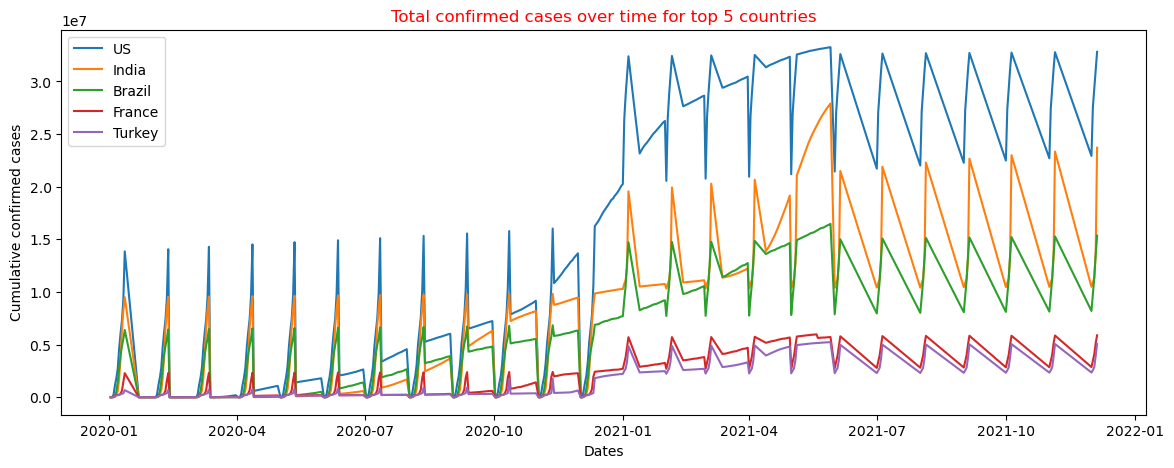

In [30]:
# we are going to plot a line chart to show the visualization over time
plt.figure(figsize=(14,5))
for country in countrylist:
        top_countries=combined_df[combined_df['Country/Region']==country].sort_values('Date')
        plt.plot(top_countries['Date'],top_countries['Confirmed cases'],label=country)
plt.title('Total confirmed cases over time for top 5 countries',color='red')
plt.xlabel('Dates')
plt.ylabel('Cumulative confirmed cases')
plt.legend()
plt.show()

#### Q2. Generate plot of confirmed cases in china

In [31]:
combined_df[combined_df['Country/Region']=='China'].sort_values('Date')['Country/Region'].value_counts()

Country/Region
China    494
Name: count, dtype: int64

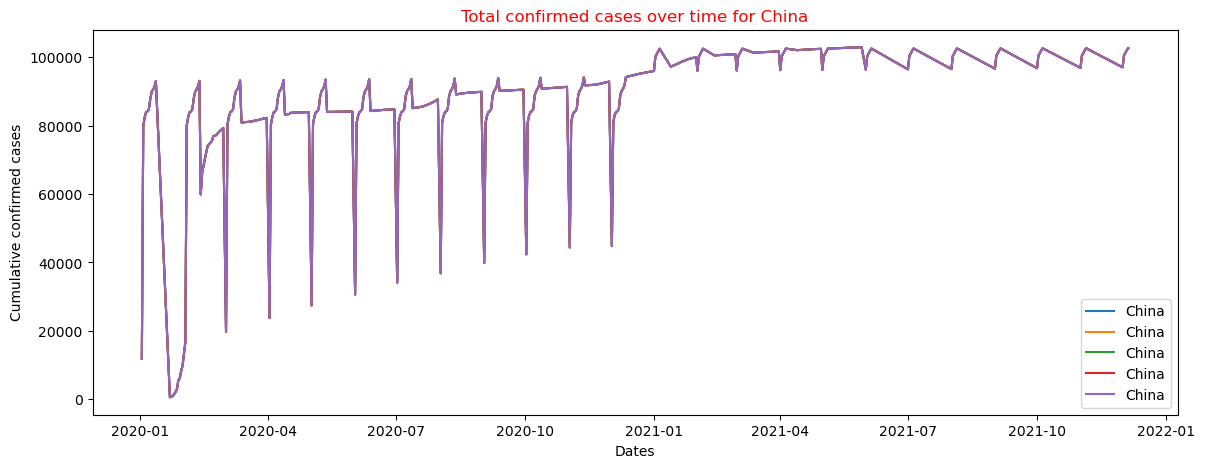

In [32]:
plt.figure(figsize=(14,5))
for country in countrylist:
        china_df=combined_df[combined_df['Country/Region']=='China'].sort_values('Date')
        plt.plot(china_df['Date'],china_df['Confirmed cases'],label='China')
plt.title('Total confirmed cases over time for China',color='red')
plt.xlabel('Dates')
plt.ylabel('Cumulative confirmed cases')
plt.legend()
plt.show()

In [33]:
# Now we'll do province visualization for china
china_df=confirm_long[confirm_long['Country/Region']=='China'].sort_values('Date').copy()
china_df

,Province/State,Country/Region,Lat,Long,Date,Confirmed cases
2851,Zhejiang,China,29.1832,120.0934,2020-01-02,599
2831,Hubei,China,30.9756,112.2707,2020-01-02,7153
2830,Hong Kong,China,22.3000,114.2000,2020-01-02,13
2829,Henan,China,37.8957,114.9042,2020-01-02,422
2828,Heilongjiang,China,47.8620,127.7615,2020-01-02,80
...,...,...,...,...,...,...
131437,Fujian,China,26.0789,117.9874,2021-12-05,597
131436,Chongqing,China,30.0572,107.8740,2021-12-05,598
131435,Beijing,China,40.1824,116.4142,2021-12-05,1057
131449,Inner Mongolia,China,44.0935,113.9448,2021-12-05,383


In [34]:
china_df=china_df.groupby(['Province/State','Date'])['Confirmed cases'].sum().reset_index()
china_df

,Province/State,Date,Confirmed cases
0,Anhui,2020-01-02,297
1,Anhui,2020-01-03,990
2,Anhui,2020-01-04,990
3,Anhui,2020-01-05,991
4,Anhui,2020-01-06,991
...,...,...,...
16791,Zhejiang,2021-12-01,1308
16792,Zhejiang,2021-12-02,1320
16793,Zhejiang,2021-12-03,1322
16794,Zhejiang,2021-12-04,1327


In [35]:
china_wide=china_df.pivot(index='Date',columns='Province/State',values='Confirmed cases').sort_index()
china_wide

Province/State,Anhui,Beijing,Chongqing,Fujian,Gansu,Guangdong,Guangxi,Guizhou,Hainan,Hebei,...,Shandong,Shanghai,Shanxi,Sichuan,Tianjin,Tibet,Unknown,Xinjiang,Yunnan,Zhejiang
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,297,168,247,144,40,535,100,29,62,96,...,206,169,47,207,41,1,0,18,93,599
2020-01-03,990,413,576,296,91,1349,252,146,168,318,...,758,337,133,538,136,1,0,76,174,1205
2020-01-04,990,580,579,345,138,1501,254,146,168,323,...,774,516,137,552,176,1,0,76,182,1257
2020-01-05,991,593,579,356,139,1588,254,147,168,328,...,787,652,197,561,190,1,0,76,185,1268
2020-01-06,991,593,579,358,139,1596,254,147,169,328,...,792,673,198,577,192,1,0,76,185,1268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-01,993,998,590,529,182,2078,264,147,171,770,...,864,1573,227,857,324,1,0,980,231,1308
2021-12-02,994,1046,591,548,187,2157,267,147,171,1316,...,867,1757,239,877,348,1,0,980,231,1320
2021-12-03,994,1049,591,553,187,2243,267,147,171,1317,...,869,1830,241,929,362,1,0,980,234,1322


In [36]:
top_prov=china_wide.iloc[-1].nlargest(5)
top_prov

Province/State
Hubei           68158
Hong Kong       11814
Guangdong        2383
Shanghai         2025
Heilongjiang     1610
Name: 2021-12-05 00:00:00, dtype: int64

In [37]:
china_wide=china_wide[top_prov.index]
china_wide

Province/State,Hubei,Hong Kong,Guangdong,Shanghai,Heilongjiang
Date,,,,,
2020-01-02,7153,13,535,169,80
2020-01-03,66907,96,1349,337,480
2020-01-04,67802,765,1501,516,484
2020-01-05,68128,1039,1588,652,944
2020-01-06,68135,1087,1596,673,945
...,...,...,...,...,...
2021-12-01,68149,9343,2078,1573,988
2021-12-02,68150,10755,2157,1757,1609
2021-12-03,68151,11210,2243,1830,1610


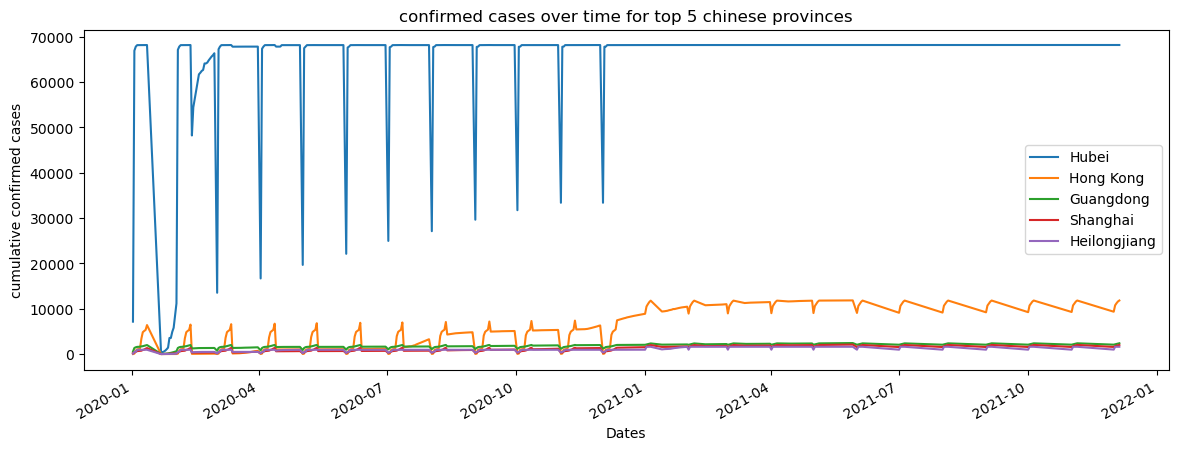

In [38]:
#visualization for top 5 provinces for china
ax=china_wide.plot(figsize=(14,5))
ax.set_title('confirmed cases over time for top 5 chinese provinces')
ax.set_xlabel('Dates')
ax.set_ylabel('cumulative confirmed cases')
ax.legend(top_prov.index)
plt.show()

#### Q3. Analyze the peak no. of new cases in Gremany, france and italy.
#### Which country experienced the highest single day surge and when did it occur

In [39]:
target_con=['France','Germany','Italy']

In [40]:
confirm_cases=confirm_agg[confirm_agg['Country/Region'].isin(target_con)]
confirm_cases

,Country/Region,Date,Confirmed cases
30628,France,2020-01-02,6
30629,France,2020-01-03,130
30630,France,2020-01-04,57122
30631,France,2020-01-05,169387
30632,France,2020-01-06,191382
...,...,...,...
42479,Italy,2021-12-01,2303263
42480,Italy,2021-12-02,2697296
42481,Italy,2021-12-03,3175807
42482,Italy,2021-12-04,3779594


In [41]:
confirm_cases=confirm_cases.groupby(['Country/Region','Date'])['Confirmed cases'].sum().reset_index()
confirm_cases

,Country/Region,Date,Confirmed cases
0,France,2020-01-02,6
1,France,2020-01-03,130
2,France,2020-01-04,57122
3,France,2020-01-05,169387
4,France,2020-01-06,191382
...,...,...,...
1477,Italy,2021-12-01,2303263
1478,Italy,2021-12-02,2697296
1479,Italy,2021-12-03,3175807
1480,Italy,2021-12-04,3779594


In [42]:
# if we want to know daily new cases, we need to subtract the previous day cases
# so like in excel we had lag and lead function, in python we have shift function
confirm_cases['Lag']=confirm_cases.groupby('Country/Region')['Confirmed cases'].shift(1)
confirm_cases

,Country/Region,Date,Confirmed cases,Lag
0,France,2020-01-02,6,NaN
1,France,2020-01-03,130,6.0
2,France,2020-01-04,57122,130.0
3,France,2020-01-05,169387,57122.0
4,France,2020-01-06,191382,169387.0
...,...,...,...,...
1477,Italy,2021-12-01,2303263,4123230.0
1478,Italy,2021-12-02,2697296,2303263.0
1479,Italy,2021-12-03,3175807,2697296.0
1480,Italy,2021-12-04,3779594,3175807.0


In [43]:
confirm_cases['Lag']=confirm_cases['Lag'].fillna(0)
confirm_cases

,Country/Region,Date,Confirmed cases,Lag
0,France,2020-01-02,6,0.0
1,France,2020-01-03,130,6.0
2,France,2020-01-04,57122,130.0
3,France,2020-01-05,169387,57122.0
4,France,2020-01-06,191382,169387.0
...,...,...,...,...
1477,Italy,2021-12-01,2303263,4123230.0
1478,Italy,2021-12-02,2697296,2303263.0
1479,Italy,2021-12-03,3175807,2697296.0
1480,Italy,2021-12-04,3779594,3175807.0


In [44]:
confirm_cases['Daily new']=confirm_cases['Confirmed cases']-confirm_cases['Lag']
confirm_cases

,Country/Region,Date,Confirmed cases,Lag,Daily new
0,France,2020-01-02,6,0.0,6.0
1,France,2020-01-03,130,6.0,124.0
2,France,2020-01-04,57122,130.0,56992.0
3,France,2020-01-05,169387,57122.0,112265.0
4,France,2020-01-06,191382,169387.0,21995.0
...,...,...,...,...,...
1477,Italy,2021-12-01,2303263,4123230.0,-1819967.0
1478,Italy,2021-12-02,2697296,2303263.0,394033.0
1479,Italy,2021-12-03,3175807,2697296.0,478511.0
1480,Italy,2021-12-04,3779594,3175807.0,603787.0


In [45]:
# ANOTHER APPROACH
country_df=confirm_agg[confirm_agg['Country/Region'].isin(target_con)]
country_df

,Country/Region,Date,Confirmed cases
30628,France,2020-01-02,6
30629,France,2020-01-03,130
30630,France,2020-01-04,57122
30631,France,2020-01-05,169387
30632,France,2020-01-06,191382
...,...,...,...
42479,Italy,2021-12-01,2303263
42480,Italy,2021-12-02,2697296
42481,Italy,2021-12-03,3175807
42482,Italy,2021-12-04,3779594


In [46]:
#pandas diff() function
#it calculates the difference of a dataframe element compared with another element in th DF (default is element in previus row)

In [47]:
country_df['Daily New']=country_df.groupby('Country/Region')['Confirmed cases'].diff().fillna(0)
country_df

C:\Users\abc\AppData\Local\Temp\ipykernel_9036\836273965.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  country_df['Daily New']=country_df.groupby('Country/Region')['Confirmed cases'].diff().fillna(0)


,Country/Region,Date,Confirmed cases,Daily New
30628,France,2020-01-02,6,0.0
30629,France,2020-01-03,130,124.0
30630,France,2020-01-04,57122,56992.0
30631,France,2020-01-05,169387,112265.0
30632,France,2020-01-06,191382,21995.0
...,...,...,...,...
42479,Italy,2021-12-01,2303263,-1819967.0
42480,Italy,2021-12-02,2697296,394033.0
42481,Italy,2021-12-03,3175807,478511.0
42482,Italy,2021-12-04,3779594,603787.0


In [48]:
#making a pivot table
daily_new_cases=(
    confirm_cases.pivot(
        index='Date',
        columns='Country/Region',
        values='Daily new'
    ).sort_index()
)
daily_new_cases

Country/Region,France,Germany,Italy
Date,,,
2020-01-02,6.0,8.0,2.0
2020-01-03,124.0,122.0,1692.0
2020-01-04,56992.0,77742.0,108880.0
2020-01-05,112265.0,86205.0,96854.0
2020-01-06,21995.0,19517.0,25769.0
...,...,...,...
2021-12-01,-2997024.0,-1589578.0,-1819967.0
2021-12-02,622313.0,362096.0,394033.0
2021-12-03,589062.0,228874.0,478511.0


In [49]:
target_con

['France', 'Germany', 'Italy']

In [50]:
daily_new_country_dict={}
for country in target_con:
    if country in daily_new_cases:
        series=daily_new_cases[country]
        daily_new_country_dict[country]=series
daily_new_country_dict

{'France': Date
 2020-01-02          6.0
 2020-01-03        124.0
 2020-01-04      56992.0
 2020-01-05     112265.0
 2020-01-06      21995.0
                 ...    
 2021-12-01   -2997024.0
 2021-12-02     622313.0
 2021-12-03     589062.0
 2021-12-04    1052405.0
 2021-12-05     754742.0
 Name: France, Length: 494, dtype: float64,
 'Germany': Date
 2020-01-02          8.0
 2020-01-03        122.0
 2020-01-04      77742.0
 2020-01-05      86205.0
 2020-01-06      19517.0
                 ...    
 2021-12-01   -1589578.0
 2021-12-02     362096.0
 2021-12-03     228874.0
 2021-12-04     465308.0
 2021-12-05     539890.0
 Name: Germany, Length: 494, dtype: float64,
 'Italy': Date
 2020-01-02          2.0
 2020-01-03       1692.0
 2020-01-04     108880.0
 2020-01-05      96854.0
 2020-01-06      25769.0
                 ...    
 2021-12-01   -1819967.0
 2021-12-02     394033.0
 2021-12-03     478511.0
 2021-12-04     603787.0
 2021-12-05     351484.0
 Name: Italy, Length: 494, dtype: floa

In [51]:
peaks={}
for country,series in daily_new_country_dict.items():
    max_value=int(series.max())
    max_index=series.idxmax().date().strftime('%Y-%m-%d')
    peaks[country]=(max_value,max_index)
peaks

{'France': (1163615, '2020-12-11'),
 'Germany': (592770, '2021-06-05'),
 'Italy': (911566, '2020-01-12')}

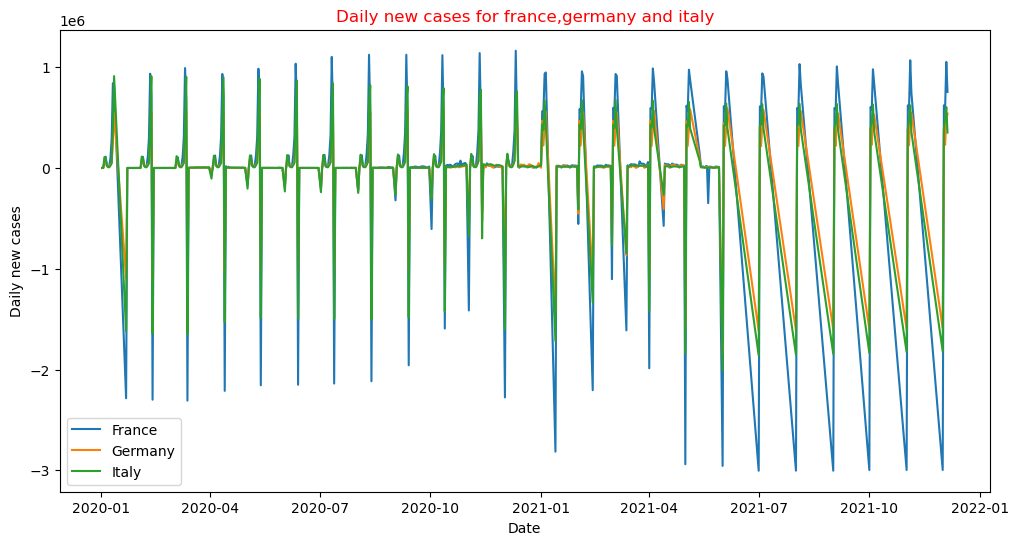

In [52]:
#visualization
plt.figure(figsize=(12,6))
for country,series in daily_new_country_dict.items():
    plt.plot(series.index,series.values,label=country)
plt.title('Daily new cases for france,germany and italy',color='red')
plt.xlabel('Date')
plt.ylabel('Daily new cases')
plt.legend()
plt.show()

#### Q4. Compare the recovery rates(recoveries/confirmed cases) between canada and australia

In [53]:
countries=['Canada','Australia']
target_date='2020-12-31'
recovery_rate=combined_df[(combined_df['Country/Region'].isin(countries))&(combined_df['Date']==target_date)]
recovery_rate

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases
4296,Australia,2020-12-31,909.0,28425,22565.0
16152,Canada,2020-12-31,15762.0,584409,493638.0


In [54]:
recovery_rate['Recovery rate']=(recovery_rate['Recovered cases']/recovery_rate['Confirmed cases']*100).round(2)
recovery_rate

C:\Users\abc\AppData\Local\Temp\ipykernel_9036\1618740010.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  recovery_rate['Recovery rate']=(recovery_rate['Recovered cases']/recovery_rate['Confirmed cases']*100).round(2)


,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Recovery rate
4296,Australia,2020-12-31,909.0,28425,22565.0,79.38
16152,Canada,2020-12-31,15762.0,584409,493638.0,84.47


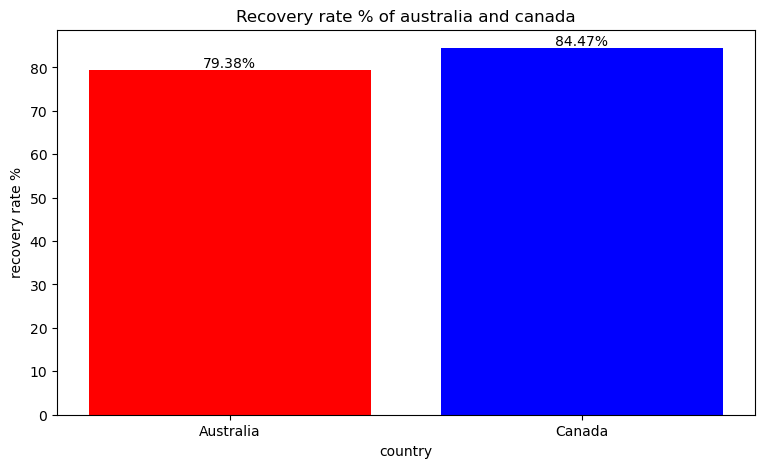

In [55]:
# visualization by column chart
plt.figure(figsize=(9,5))
bars=plt.bar(recovery_rate['Country/Region'],recovery_rate['Recovery rate'],color=['red','blue'])
plt.title('Recovery rate % of australia and canada')
plt.xlabel('country')
plt.ylabel('recovery rate %')
plt.bar_label(bars,fmt='%.2f%%')
plt.show()

#### Q5. What is the distribution of death rates among provinces in canada. Identify the province with the highest and lowest death rate as of the latest data point

In [56]:
confirm_long[confirm_long['Country/Region']=='Canada']

,Province/State,Country/Region,Lat,Long,Date,Confirmed cases
39,Alberta,Canada,53.9333,-116.5765,2020-01-22,0
40,British Columbia,Canada,53.7267,-127.6476,2020-01-22,0
41,Diamond Princess,Canada,0.0000,0.0000,2020-01-22,0
42,Grand Princess,Canada,0.0000,0.0000,2020-01-22,0
43,Manitoba,Canada,53.7609,-98.8139,2020-01-22,0
...,...,...,...,...,...,...
136118,Prince Edward Island,Canada,46.5107,-63.4168,2021-05-29,200
136119,Quebec,Canada,52.9399,-73.5491,2021-05-29,369728
136120,Repatriated Travellers,Canada,0.0000,0.0000,2021-05-29,13
136121,Saskatchewan,Canada,52.9399,-106.4509,2021-05-29,46464


In [57]:
death_long[death_long['Country/Region']=='Canada']

,Province/State,Country/Region,Lat,Long,Date,Deaths
39,Alberta,Canada,53.9333,-116.5765,2020-01-22,0.0
40,British Columbia,Canada,53.7267,-127.6476,2020-01-22,0.0
41,Diamond Princess,Canada,0.0000,0.0000,2020-01-22,0.0
42,Grand Princess,Canada,0.0000,0.0000,2020-01-22,0.0
43,Manitoba,Canada,53.7609,-98.8139,2020-01-22,0.0
...,...,...,...,...,...,...
136118,Prince Edward Island,Canada,46.5107,-63.4168,2021-05-29,0.0
136119,Quebec,Canada,52.9399,-73.5491,2021-05-29,11125.0
136120,Repatriated Travellers,Canada,0.0000,0.0000,2021-05-29,0.0
136121,Saskatchewan,Canada,52.9399,-106.4509,2021-05-29,537.0


In [58]:
confirm_cases_canada=(
    confirm_long[confirm_long['Country/Region']=='Canada']
    .sort_values('Date').groupby(['Province/State']).tail(1)[['Province/State','Confirmed cases']]
    .set_index('Province/State')
)
confirm_cases_canada                 

,Confirmed cases
Province/State,
Saskatchewan,43673
Alberta,213635
British Columbia,137223
Diamond Princess,0
Grand Princess,13
Manitoba,43143
New Brunswick,2024
Newfoundland and Labrador,1166
Nova Scotia,4301


In [59]:
death_cases_canada=(
    death_long[death_long['Country/Region']=='Canada']
    .sort_values('Date').groupby(['Province/State']).tail(1)[['Province/State','Deaths']]
    .set_index('Province/State')
)
death_cases_canada  

,Deaths
Province/State,
Saskatchewan,508.0
Alberta,2123.0
British Columbia,1627.0
Diamond Princess,1.0
Grand Princess,0.0
Manitoba,1000.0
New Brunswick,41.0
Newfoundland and Labrador,6.0
Nova Scotia,71.0


In [60]:
canada_df=confirm_cases_canada.join(death_cases_canada,how='inner')
canada_df

,Confirmed cases,Deaths
Province/State,,
Saskatchewan,43673,508.0
Alberta,213635,2123.0
British Columbia,137223,1627.0
Diamond Princess,0,1.0
Grand Princess,13,0.0
Manitoba,43143,1000.0
New Brunswick,2024,41.0
Newfoundland and Labrador,1166,6.0
Nova Scotia,4301,71.0


In [61]:
canada_df['Death rate %']=(canada_df['Deaths']/canada_df['Confirmed cases']*100).round(2)
canada_df

,Confirmed cases,Deaths,Death rate %
Province/State,,,
Saskatchewan,43673,508.0,1.16
Alberta,213635,2123.0,0.99
British Columbia,137223,1627.0,1.19
Diamond Princess,0,1.0,inf
Grand Princess,13,0.0,0.00
Manitoba,43143,1000.0,2.32
New Brunswick,2024,41.0,2.03
Newfoundland and Labrador,1166,6.0,0.51
Nova Scotia,4301,71.0,1.65


In [62]:
#Above, we were dividing 1 by 0 and getting infinity .... but we don't want that.... so we will now replace infinity with 0
import numpy as np
canada_df['Death rate %']=(canada_df['Deaths']/canada_df['Confirmed cases']*100).round(2).replace(np.inf,0)
canada_df

,Confirmed cases,Deaths,Death rate %
Province/State,,,
Saskatchewan,43673,508.0,1.16
Alberta,213635,2123.0,0.99
British Columbia,137223,1627.0,1.19
Diamond Princess,0,1.0,0.00
Grand Princess,13,0.0,0.00
Manitoba,43143,1000.0,2.32
New Brunswick,2024,41.0,2.03
Newfoundland and Labrador,1166,6.0,0.51
Nova Scotia,4301,71.0,1.65


In [63]:
canada_df.sort_values(by='Death rate %')

,Confirmed cases,Deaths,Death rate %
Province/State,,,
Diamond Princess,0,1.0,0.00
Grand Princess,13,0.0,0.00
Repatriated Travellers,13,0.0,0.00
Prince Edward Island,187,0.0,0.00
Northwest Territories,120,0.0,0.00
Newfoundland and Labrador,1166,6.0,0.51
Nunavut,594,4.0,0.67
Alberta,213635,2123.0,0.99
Saskatchewan,43673,508.0,1.16


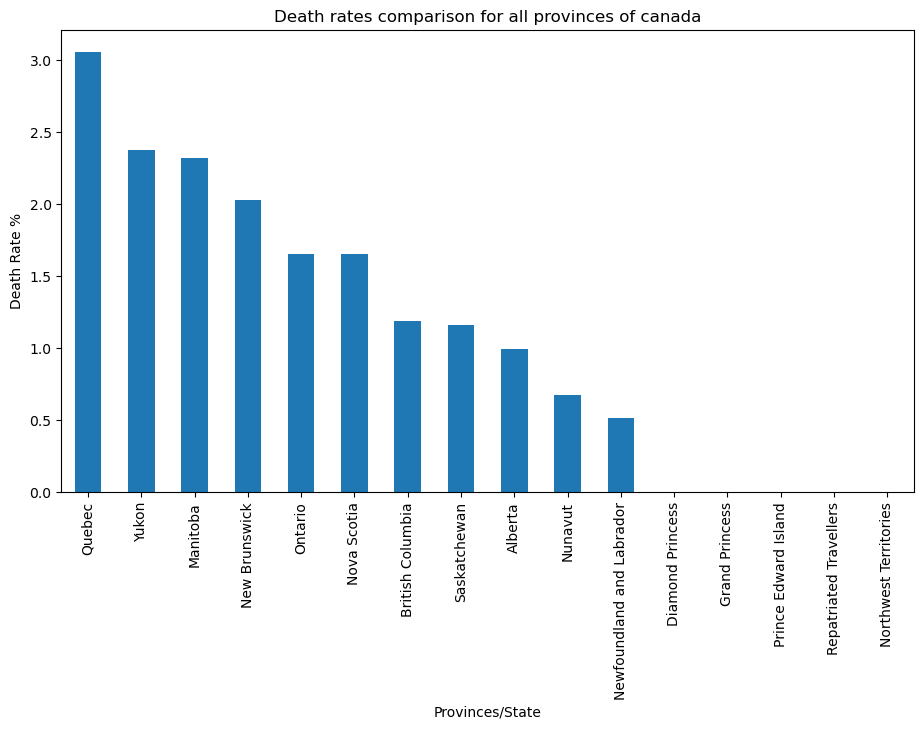

In [64]:
#visualization
plt.figure(figsize=(11,6))
canada_df['Death rate %'].sort_values(ascending=False).plot(kind='bar')
plt.title('Death rates comparison for all provinces of canada')
plt.xlabel('Provinces/State')
plt.ylabel('Death Rate %')
plt.show()

#### Q6. What is the total no.of deaths reported per country upto the current date

In [65]:
latest_date=combined_df['Date'].max()
latest_date

Timestamp('2021-12-05 00:00:00')

In [66]:
# we have cumulative deaths ; so we need to use .diff() to make the difference from the previous row and find daily deaths
death_df=combined_df.sort_values(['Country/Region','Date']).copy()
death_df['Daily Deaths']=combined_df.groupby(['Country/Region'])['Deaths'].diff().fillna(0)
death_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Daily Deaths
0,Afghanistan,2020-01-02,0.0,0,0.0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0,0.0
2,Afghanistan,2020-01-04,4.0,197,5.0,4.0
3,Afghanistan,2020-01-05,68.0,2291,310.0,64.0
4,Afghanistan,2020-01-06,266.0,15753,1428.0,198.0
...,...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0,-1028.0
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0,842.0
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0,103.0
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0,46.0


In [67]:
total_death_by_country=(
    death_df.groupby('Country/Region')['Daily Deaths'].sum()
).nlargest(10).reset_index()
total_death_by_country

,Country/Region,Daily Deaths
0,US,583942.0
1,Brazil,428034.0
2,India,258317.0
3,Mexico,219590.0
4,United Kingdom,127901.0
5,Italy,123544.0
6,Russia,112410.0
7,France,107280.0
8,Germany,85451.0
9,Colombia,79261.0


#### Q7. What are the top 5 countries with the highest avg daily deaths

In [68]:
total_death_by_country=(
    death_df.groupby('Country/Region')['Daily Deaths'].mean().round(2)
).nlargest(5).reset_index()
total_death_by_country

,Country/Region,Daily Deaths
0,US,1182.07
1,Brazil,866.47
2,India,522.91
3,Mexico,444.51
4,United Kingdom,258.91


#### Q8. How have the total deaths evolved over time in US

In [69]:
death_long

,Province/State,Country/Region,Lat,Long,Date,Deaths
0,All Provinces,Afghanistan,33.939110,67.709953,2020-01-22,0.0
1,All Provinces,Albania,41.153300,20.168300,2020-01-22,0.0
2,All Provinces,Algeria,28.033900,1.659600,2020-01-22,0.0
3,All Provinces,Andorra,42.506300,1.521800,2020-01-22,0.0
4,All Provinces,Angola,-11.202700,17.873900,2020-01-22,0.0
...,...,...,...,...,...,...
136339,All Provinces,Vietnam,14.058324,108.277199,2021-05-29,47.0
136340,All Provinces,West Bank and Gaza,31.952200,35.233200,2021-05-29,3492.0
136341,All Provinces,Yemen,15.552727,48.516388,2021-05-29,1319.0
136342,All Provinces,Zambia,-13.133897,27.849332,2021-05-29,1276.0


In [70]:
us_death_over_time=(
    death_long[death_long['Country/Region']=='US']
    .groupby('Date')['Deaths'].sum()
)
us_death_over_time

Date
2020-01-02         0.0
2020-01-03         1.0
2020-01-04      6653.0
2020-01-05     68144.0
2020-01-06    108616.0
                ...   
2021-12-01    388001.0
2021-12-02    484494.0
2021-12-03    534234.0
2021-12-04    563103.0
2021-12-05    583942.0
Name: Deaths, Length: 494, dtype: float64

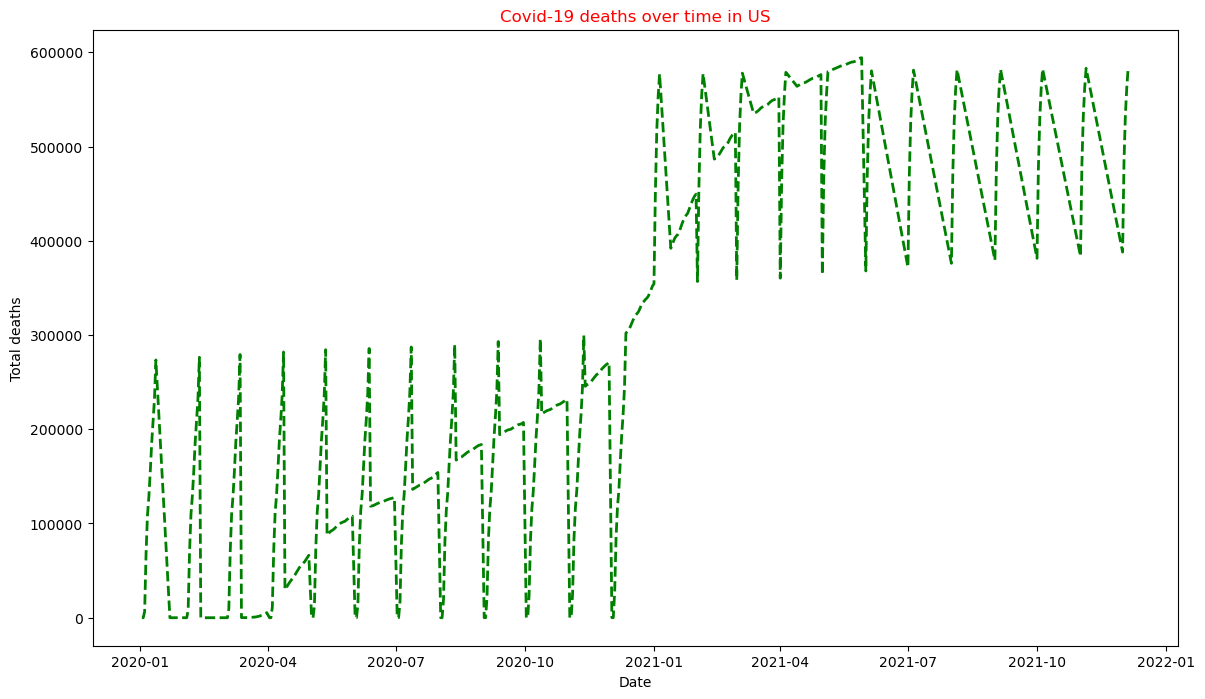

In [71]:
# visualization
plt.figure(figsize=(14,8))
plt.plot(us_death_over_time.index,us_death_over_time.values,color='green',linewidth=2,linestyle='--')
plt.title('Covid-19 deaths over time in US', color='red')
plt.xlabel('Date')
plt.ylabel('Total deaths')
plt.show()

#### Q9. Analyze the monthly sum of confirmed cases, deaths, recovered cases to understand the prgression of the pandemic

In [72]:
monthly_df=combined_df.copy()
monthly_df=monthly_df.sort_values(['Country/Region','Date'])
monthly_df['Year Month']=monthly_df['Date'].dt.to_period('M')
monthly_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01
2,Afghanistan,2020-01-04,4.0,197,5.0,2020-01
3,Afghanistan,2020-01-05,68.0,2291,310.0,2020-01
4,Afghanistan,2020-01-06,266.0,15753,1428.0,2020-01
...,...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0,2021-12
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0,2021-12
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0,2021-12
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0,2021-12


In [73]:
# Daily confirmed
confirm_diff=combined_df.groupby('Country/Region')['Confirmed cases'].diff().fillna(0)
monthly_df['Daily confirmed']=confirm_diff

#daily deaths
death_diff=combined_df.groupby('Country/Region')['Deaths'].diff().fillna(0)
monthly_df['Daily deaths']=death_diff

#daily recovered
recover_diff=combined_df.groupby('Country/Region')['Recovered cases'].diff().fillna(0)
monthly_df['Daily recovered']=recover_diff

In [74]:
monthly_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month,Daily confirmed,Daily deaths,Daily recovered
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01,0.0,0.0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01,1.0,0.0,0.0
2,Afghanistan,2020-01-04,4.0,197,5.0,2020-01,196.0,4.0,5.0
3,Afghanistan,2020-01-05,68.0,2291,310.0,2020-01,2094.0,64.0,305.0
4,Afghanistan,2020-01-06,266.0,15753,1428.0,2020-01,13462.0,198.0,1118.0
...,...,...,...,...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0,2021-12,-15209.0,-1028.0,-22825.0
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0,2021-12,11806.0,842.0,16563.0
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0,2021-12,1378.0,103.0,4037.0
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0,2021-12,884.0,46.0,905.0


In [75]:
monthly_data=(
    monthly_df.groupby(['Country/Region','Year Month'])[['Daily confirmed','Daily deaths','Daily recovered']]
    .sum()
).astype(int).reset_index().sort_values(['Country/Region','Year Month'])
monthly_data

,Country/Region,Year Month,Daily confirmed,Daily deaths,Daily recovered
0,Afghanistan,2020-01,0,0,0
1,Afghanistan,2020-02,1,0,0
2,Afghanistan,2020-03,174,4,5
3,Afghanistan,2020-04,1952,60,255
4,Afghanistan,2020-05,13081,194,1068
...,...,...,...,...,...
4627,Zimbabwe,2021-08,11,0,11
4628,Zimbabwe,2021-09,5,0,11
4629,Zimbabwe,2021-10,14,0,145
4630,Zimbabwe,2021-11,15,3,13


#### Q10. Redo the above analysis in last question for US, Italy and Brazil

In [76]:
country_agg_df=combined_df.copy()
country_agg_df=country_agg_df.sort_values(['Country/Region','Date'])
country_agg_df['Year Month']=country_agg_df['Date'].dt.to_period('M')
country_agg_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01
2,Afghanistan,2020-01-04,4.0,197,5.0,2020-01
3,Afghanistan,2020-01-05,68.0,2291,310.0,2020-01
4,Afghanistan,2020-01-06,266.0,15753,1428.0,2020-01
...,...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0,2021-12
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0,2021-12
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0,2021-12
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0,2021-12


In [77]:
# Daily confirmed
confirm_diff=combined_df.groupby('Country/Region')['Confirmed cases'].diff().fillna(0).clip(lower=0)
country_agg_df['Daily confirmed']=confirm_diff

#daily deaths
death_diff=combined_df.groupby('Country/Region')['Deaths'].diff().fillna(0).clip(lower=0)
country_agg_df['Daily deaths']=death_diff

#daily recovered
recover_diff=combined_df.groupby('Country/Region')['Recovered cases'].diff().fillna(0).clip(lower=0)
country_agg_df['Daily recovered']=recover_diff
#clip() function was used to remove the negative values

In [78]:
country_agg_df

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month,Daily confirmed,Daily deaths,Daily recovered
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01,0.0,0.0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01,1.0,0.0,0.0
2,Afghanistan,2020-01-04,4.0,197,5.0,2020-01,196.0,4.0,5.0
3,Afghanistan,2020-01-05,68.0,2291,310.0,2020-01,2094.0,64.0,305.0
4,Afghanistan,2020-01-06,266.0,15753,1428.0,2020-01,13462.0,198.0,1118.0
...,...,...,...,...,...,...,...,...,...
95337,Zimbabwe,2021-12-01,551.0,23239,13396.0,2021-12,0.0,0.0,0.0
95338,Zimbabwe,2021-12-02,1393.0,35045,29959.0,2021-12,11806.0,842.0,16563.0
95339,Zimbabwe,2021-12-03,1496.0,36423,33996.0,2021-12,1378.0,103.0,4037.0
95340,Zimbabwe,2021-12-04,1542.0,37307,34901.0,2021-12,884.0,46.0,905.0


In [79]:
monthly_sum=(
    country_agg_df.groupby(['Country/Region','Year Month'])[['Daily confirmed','Daily deaths','Daily recovered']]
    .sum()
    .rename(columns={
        'Daily confirmed' : 'Monthly confirmed',
        'Daily deaths' : 'Monthly deaths',
        'Daily recovered' : "Monthly recovered"
    })
        .reset_index()
            .sort_values(['Country/Region','Year Month'])
           )
monthly_sum

,Country/Region,Year Month,Monthly confirmed,Monthly deaths,Monthly recovered
0,Afghanistan,2020-01,46516.0,1822.0,36946.0
1,Afghanistan,2020-02,46719.0,1841.0,37218.0
2,Afghanistan,2020-03,46999.0,1850.0,37265.0
3,Afghanistan,2020-04,48298.0,1888.0,37488.0
4,Afghanistan,2020-05,57053.0,1990.0,38073.0
...,...,...,...,...,...
4627,Zimbabwe,2021-08,18754.0,1108.0,23868.0
4628,Zimbabwe,2021-09,17920.0,1093.0,23624.0
4629,Zimbabwe,2021-10,16956.0,1069.0,23626.0
4630,Zimbabwe,2021-11,16151.0,1051.0,23008.0


In [80]:
us_monthly_trends=monthly_sum[monthly_sum['Country/Region']=='US']
us_monthly_trends

,Country/Region,Year Month,Monthly confirmed,Monthly deaths,Monthly recovered
4296,US,2020-01,13858550.0,273566.0,5226581.0
4297,US,2020-02,14061111.0,276382.0,5322132.0
4298,US,2020-03,14474792.0,284656.0,5411030.0
4299,US,2020-04,15000135.0,318584.0,5580854.0
4300,US,2020-05,15130106.0,304723.0,5777354.0
4301,US,2020-06,15482258.0,295041.0,5788469.0
4302,US,2020-07,16306118.0,305319.0,6120778.0
4303,US,2020-08,16110842.0,306489.0,6197092.0
4304,US,2020-09,16268451.0,306076.0,6279175.0
4305,US,2020-10,17087088.0,311506.0,6472929.0


In [81]:
italy_monthly_trends=monthly_sum[monthly_sum['Country/Region']=='Italy']
italy_monthly_trends

,Country/Region,Year Month,Monthly confirmed,Monthly deaths,Monthly recovered
2040,Italy,2020-01,1620901.0,56361.0,784595.0
2041,Italy,2020-02,1642733.0,57074.0,823382.0
2042,Italy,2020-03,1752959.0,69200.0,861099.0
2043,Italy,2020-04,1734884.0,66354.0,912895.0
2044,Italy,2020-05,1720882.0,61823.0,941274.0
2045,Italy,2020-06,1732951.0,60575.0,928877.0
2046,Italy,2020-07,1746861.0,60780.0,938000.0
2047,Italy,2020-08,1774370.0,61492.0,964242.0
2048,Italy,2020-09,1797254.0,62023.0,1011965.0
2049,Italy,2020-10,2101107.0,64998.0,1075392.0


In [82]:
brazil_monthly_trends=monthly_sum[monthly_sum['Country/Region']=='Brazil']
brazil_monthly_trends

,Country/Region,Year Month,Monthly confirmed,Monthly deaths,Monthly recovered
552,Brazil,2020-01,6386787.0,173817.0,5712305.0
553,Brazil,2020-02,6436652.0,174515.0,5759294.0
554,Brazil,2020-03,6492650.0,175471.0,5792666.0
555,Brazil,2020-04,6597725.0,180642.0,5861507.0
556,Brazil,2020-05,6901889.0,192702.0,5992969.0
557,Brazil,2020-06,7155067.0,193815.0,6195539.0
558,Brazil,2020-07,7401429.0,196959.0,6615129.0
559,Brazil,2020-08,7358395.0,194077.0,6712983.0
560,Brazil,2020-09,7208932.0,191322.0,6517686.0
561,Brazil,2020-10,7203776.0,188651.0,6521987.0


#### Q11. For the combined dataset, identify the three countries with the highest avg death rates(deaths/confirmed cases) throughout 2020.

In [83]:
df_2020=country_agg_df[country_agg_df['Year Month'].between('2020-01','2020-12')]
df_2020

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month,Daily confirmed,Daily deaths,Daily recovered
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01,0.0,0.0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01,1.0,0.0,0.0
2,Afghanistan,2020-01-04,4.0,197,5.0,2020-01,196.0,4.0,5.0
3,Afghanistan,2020-01-05,68.0,2291,310.0,2020-01,2094.0,64.0,305.0
4,Afghanistan,2020-01-06,266.0,15753,1428.0,2020-01,13462.0,198.0,1118.0
...,...,...,...,...,...,...,...,...,...
95188,Zimbabwe,2020-12-27,349.0,13077,10593.0,2020-12,114.0,8.0,74.0
95189,Zimbabwe,2020-12-28,354.0,13148,10705.0,2020-12,71.0,5.0,112.0
95190,Zimbabwe,2020-12-29,359.0,13325,11067.0,2020-12,177.0,5.0,362.0
95191,Zimbabwe,2020-12-30,360.0,13625,11154.0,2020-12,300.0,1.0,87.0


In [84]:
overall_2020=(
    df_2020.groupby('Country/Region')[['Daily confirmed','Daily deaths']]
    .sum()
    .rename(columns={
        'Daily confirmed':'confirmed2020',
        'Daily deaths':'deaths2020'}
           ))
overall_2020

,confirmed2020,deaths2020
Country/Region,,
Afghanistan,599231.0,23932.0
Albania,555210.0,11630.0
Algeria,1119219.0,32190.0
Andorra,89623.0,983.0
Angola,198555.0,4520.0
...,...,...
Vietnam,17146.0,437.0
West Bank and Gaza,1269538.0,11035.0
Yemen,26055.0,7613.0


In [85]:
overall_2020['Death rate %']=(overall_2020['deaths2020']/overall_2020['confirmed2020']*100).round(2)
overall_2020

,confirmed2020,deaths2020,Death rate %
Country/Region,,,
Afghanistan,599231.0,23932.0,3.99
Albania,555210.0,11630.0,2.09
Algeria,1119219.0,32190.0,2.88
Andorra,89623.0,983.0,1.10
Angola,198555.0,4520.0,2.28
...,...,...,...
Vietnam,17146.0,437.0,2.55
West Bank and Gaza,1269538.0,11035.0,0.87
Yemen,26055.0,7613.0,29.22


In [86]:
top_3=overall_2020.sort_values(by='Death rate %',ascending=False).head(3)
top_3

,confirmed2020,deaths2020,Death rate %
Country/Region,,,
Yemen,26055.0,7613.0,29.22
MS Zaandam,110.0,24.0,21.82
Mexico,15008863.0,1395249.0,9.30


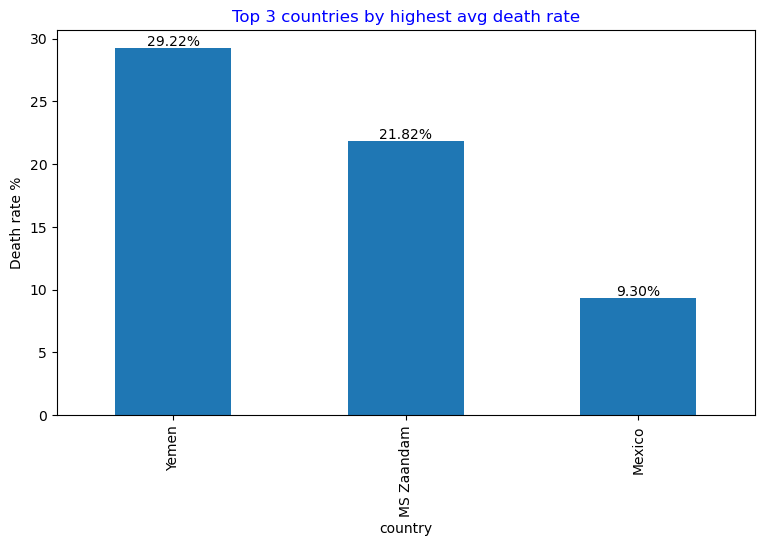

In [87]:
#visualization by bar chart 
ax=top_3['Death rate %'].plot(kind='bar',figsize=(9,5))
ax.set_title('Top 3 countries by highest avg death rate',color='blue')
ax.set_xlabel('country')
ax.set_ylabel('Death rate %')
ax.bar_label(ax.containers[0],fmt='%.2f%%')
plt.show()

#### Q12. Using the merged dataset, compare the total no. of recoveries to the total no. of deaths in south africa.

In [88]:
country_agg_df.head(2)

,Country/Region,Date,Deaths,Confirmed cases,Recovered cases,Year Month,Daily confirmed,Daily deaths,Daily recovered
0,Afghanistan,2020-01-02,0.0,0,0.0,2020-01,0.0,0.0,0.0
1,Afghanistan,2020-01-03,0.0,1,0.0,2020-01,1.0,0.0,0.0


In [89]:
df=country_agg_df
total_recoveries=df[df['Country/Region']=='South Africa']['Daily recovered'].sum()
total_recoveries=int(total_recoveries)
total_recoveries

16831548

In [90]:
total_deaths=df[df['Country/Region']=='South Africa']['Daily deaths'].sum()
total_deaths=int(total_deaths)
total_deaths

579240

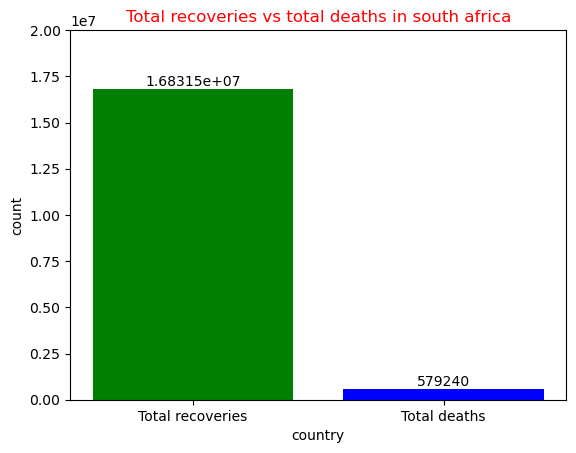

In [91]:
#visualization
bars=plt.bar(['Total recoveries','Total deaths'],[total_recoveries,total_deaths],color=['green','blue'])
plt.title('Total recoveries vs total deaths in south africa', color='red')
plt.xlabel('country')
plt.ylabel('count')
plt.ylim(0,20000000)
plt.bar_label(bars)
plt.show()

#### Q13. Analyze the ratio of recoveries to confirmed cases for thr US on a monthly basis from march 2020 to may2021. which month experienced thr highest recovery ratio and what could be the potential reasons

In [92]:
us_df=monthly_sum[monthly_sum['Country/Region']=='US'].sort_values('Year Month').set_index('Year Month')
us_df

,Country/Region,Monthly confirmed,Monthly deaths,Monthly recovered
Year Month,,,,
2020-01,US,13858550.0,273566.0,5226581.0
2020-02,US,14061111.0,276382.0,5322132.0
2020-03,US,14474792.0,284656.0,5411030.0
2020-04,US,15000135.0,318584.0,5580854.0
2020-05,US,15130106.0,304723.0,5777354.0
2020-06,US,15482258.0,295041.0,5788469.0
2020-07,US,16306118.0,305319.0,6120778.0
2020-08,US,16110842.0,306489.0,6197092.0
2020-09,US,16268451.0,306076.0,6279175.0


In [93]:
recovery_ratio=us_df['Monthly recovered']/us_df['Monthly confirmed']
recovery_ratio=recovery_ratio.loc['2020-03':'2021-05']
recovery_ratio

Year Month
2020-03    0.373824
2020-04    0.372054
2020-05    0.381845
2020-06    0.373878
2020-07    0.375367
2020-08    0.384654
2020-09    0.385973
2020-10    0.378820
2020-11    0.381264
2020-12    0.313347
2021-01    0.000000
2021-02    0.000000
2021-03    0.000000
2021-04    0.000000
2021-05    0.000000
Freq: M, dtype: float64

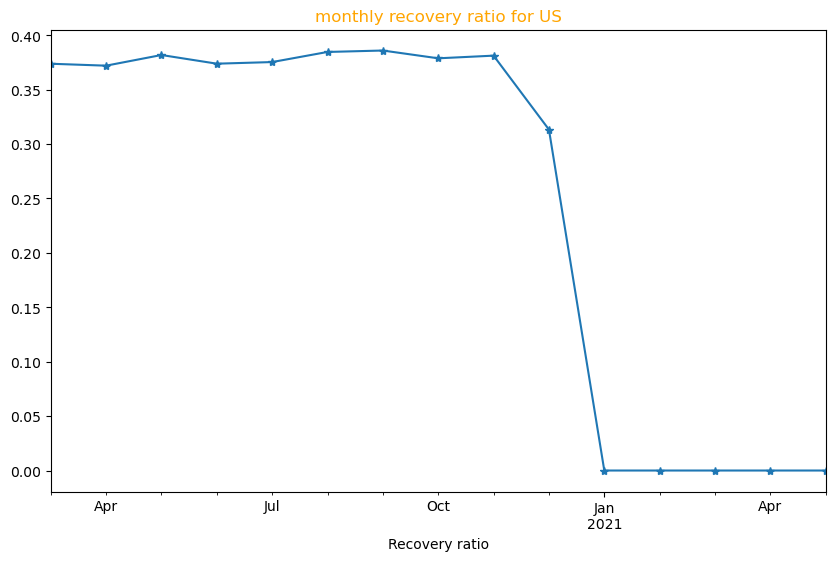

In [94]:
#visualization
fig,ax=plt.subplots(figsize=(10,6))
recovery_ratio.plot(kind='line',marker='*',linestyle='-')
ax.set_title('monthly recovery ratio for US' , color='orange')
ax.set_xlabel('Year Month')
ax.set_xlabel('Recovery ratio')
plt.show()
